In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not on colab')

Mounted at /content/drive


# Movie Recommender System using MovieLens data (model selection)
Author: Michael Fitiavana Randriamifidy

Created: 27 December 2025

Last Updated:  10 january 2026

In [2]:
!pip install AdjustText -q

In [3]:
import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

In [4]:
DATA_SIZE_DICT= {
    0: "ml-latest-small",
    1: "ml-25m ",
    2: "ml-32m",
}
DATA_SIZE_STR = DATA_SIZE_DICT[2]

# Setting up

In [5]:
import importlib
sys.modules["imp"] = importlib
%load_ext autoreload
%reload_ext autoreload
%autoreload 2

## Setting up Notebooks

In [6]:
from typing import Optional, Callable, Dict, Any, List

def download_and_extract_movielens(
                            data_folders:List[str],
                            extracted_data_folder:str='./data',
                            data_size_str:str='ml-latest-small',
                            only_extract:bool=True
                            ):
    pattern = re.compile(rf"{data_size_str}\.zip$")
    for data_folder in data_folders:
        matches = [p for p in Path(data_folder).iterdir() if pattern.match(p.name)]
        if matches:
            print("Found zip file(s):", str(matches[-1]))
            break
    if not  matches:
        print(f"Downloading:{data_size_str}.zip from https://files.grouplens.org/datasets/movielens/{data_size_str}.zip")
        !curl -C - -O --output-dir "{data_folder}" "https://files.grouplens.org/datasets/movielens/{data_size_str}.zip"
    print(f"Extract to {extracted_data_folder}")
    !unzip -n "{data_folder}/{data_size_str}.zip" -d "{extracted_data_folder}"


    pattern = re.compile(rf"{data_size_str}\.zip.md5$")
    for data_folder in data_folders:
        matches = [p for p in Path(data_folder).iterdir() if pattern.match(str(p))]
        if matches:
            print("Found zip.md5 file(s):", str(matches[-1]))
            break
    if not  matches:
        print(f"Downloading:{data_size_str}.zip.md5 from https://files.grouplens.org/datasets/movielens/{data_size_str}.zip.md5")
        !curl -C - -O --output-dir "{data_folder}"  "https://files.grouplens.org/datasets/movielens/{data_size_str}.zip.md5"

def is_kaggle() -> bool:
    """
    Detect if the code is running on Kaggle.

    Returns:
        bool: True if running on Kaggle, False otherwise.
    """
    return "KAGGLE_URL_BASE" in os.environ


def is_colab() -> bool:
    """
    Detect if the code is running on Google Colab.

    Returns:
        bool: True if running on Google Colab, False otherwise.
    """
    try:
        import google.colab
        return True
    except ImportError:
        return False


def set_project(
    fun_todo_kaggle: Optional[Callable[..., Any]] = None,
    fun_todo_colab: Optional[Callable[..., Any]] = None,
    fun_todo_local: Optional[Callable[..., Any]] = None,
    kwargs_kaggle: Optional[Dict[str, Any]] = None,
    kwargs_colab: Optional[Dict[str, Any]] = None,
    kwargs_local: Optional[Dict[str, Any]] = None
) -> Optional[Any]:
    """
    Execute platform-specific setup functions based on the current environment.

    This function detects whether code is running on Kaggle, Google Colab, or locally,
    and executes the corresponding setup function with the provided keyword arguments.

    Args:
        fun_todo_kaggle: Optional function to execute on Kaggle.
        fun_todo_colab: Optional function to execute on Google Colab.
        fun_todo_local: Optional function to execute locally.
        kwargs_kaggle: Keyword arguments to pass to the Kaggle function.
        kwargs_colab: Keyword arguments to pass to the Colab function.
        kwargs_local: Keyword arguments to pass to the local function.

    Returns:
        The return value of the executed function, or None if no function is provided
        for the detected environment.
    """
    # Initialize kwargs dictionaries if None
    kwargs_kaggle = kwargs_kaggle or {}
    kwargs_colab = kwargs_colab or {}
    kwargs_local = kwargs_local or {}

    # Conditional commands
    if is_kaggle():
        print("Running on Kaggle")
        if fun_todo_kaggle is not None:
            return fun_todo_kaggle(**kwargs_kaggle)
    elif is_colab():
        print("Running on Google Colab")
        if fun_todo_colab is not None:
            return fun_todo_colab(**kwargs_colab)
    else:
        print("Running locally")
        if fun_todo_local is not None:
            return fun_todo_local(**kwargs_local)

    return None

def is_drive_mounted():
    return os.path.exists("/content/drive/MyDrive")


def fun_todo_kaggle(**kwargs):
    data_size_str = kwargs['data_size_str'] if "data_size_str" in kwargs else "latest-small"
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    # os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(f"/kaggle/working/movie-recommender-system-{data_size_str}")
    PROJECT_PATH = Path("/kaggle/temp/")
    DATA_FOLDER = PROJECT_PATH / "download/data"
    EXTRACTED_DATA_FOLDER = Path("/kaggle/input/movielens-dataset/")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20
    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER

def fun_todo_colab(**kwargs):
    if is_drive_mounted():
        print("Google Drive is already mounted")
    else:
        raise "Mount Drive"

    data_size_str = kwargs['data_size_str'] if "data_size_str" in kwargs else "latest-small"
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    # os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(project_dir_abs) / f"working/movie-recommender-system-{data_size_str}"
    PROJECT_PATH =  Path(project_dir_abs) / f"temp/movie-recommender-system-{data_size_str}"
    DATA_FOLDER = Path("./downloads/data")
    EXTRACTED_DATA_FOLDER = Path("./data")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20

    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)
    download_and_extract_movielens(
        [DATA_FOLDER, project_dir_abs / DATA_FOLDER],
        EXTRACTED_DATA_FOLDER,
        data_size_str = DATA_SIZE_STR)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER

def fun_todo_local(**kwargs):
    data_size_str = kwargs.get('data_size_str', 'latest-small')
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(project_dir_abs) / f"working/movie-recommender-system-{data_size_str}"
    PROJECT_PATH =  Path(project_dir_abs) / f"temp/movie-recommender-system-{data_size_str}"
    DATA_FOLDER = Path("./downloads/data")
    EXTRACTED_DATA_FOLDER = Path("./data")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20
    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)

    download_and_extract_movielens(
        [DATA_FOLDER, project_dir_abs / DATA_FOLDER],
        EXTRACTED_DATA_FOLDER,
        data_size_str = DATA_SIZE_STR)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER


In [7]:
if Path.cwd().name == "notebooks":
    PROJECT_DIR_ABS = Path.cwd().parent
else:
    PROJECT_DIR_ABS = Path.cwd()
print(f"MovieLens data:{DATA_SIZE_STR}")
kwargs = {"data_size_str":DATA_SIZE_STR}
kwargs_kaggle = {**kwargs, **{'project_dir_abs':Path(f"/kaggle/input/movie-recommender-system-{DATA_SIZE_STR}")}}
kwargs_colab = {**kwargs, **{'project_dir_abs':Path(f"/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system")}}
kwargs_local = {**kwargs, **{'project_dir_abs':PROJECT_DIR_ABS}}
(
    REMOTE_PROJECT_PATH,
    PROJECT_PATH,
    DATA_FOLDER,
    EXTRACTED_DATA_FOLDER
    ) = set_project(fun_todo_kaggle,
                    fun_todo_colab,
                    fun_todo_local,
                    kwargs_kaggle=kwargs_kaggle,
                    kwargs_colab=kwargs_colab,
                    kwargs_local=kwargs_local)

ratings_path = EXTRACTED_DATA_FOLDER / DATA_SIZE_STR / "ratings.csv"
movies_path = EXTRACTED_DATA_FOLDER / DATA_SIZE_STR / "movies.csv"
PLOT_FOLDER = PROJECT_PATH / "plots"
MODEL_FOLDER = PROJECT_PATH / "models"
REMOTE_MODEL_FOLDER = REMOTE_PROJECT_PATH / "models"

MovieLens data:ml-32m
Running on Google Colab
Google Drive is already mounted
/content
/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m:
models

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m/models:
with_embeddings
with_features

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m/models/with_embeddings:
ml-32m-als-K02-best_nepochs14-maxiter50-lambda1-tau0.1-with_embeddings-latest.joblib
ml-32m-als-K02-best_nepochs21-maxiter50-lambda1-tau10-with_embeddings-latest.joblib
ml-32m-als-K02-best_nepochs23-maxiter50-lambda1-tau1-with_embeddings-latest.joblib
ml-32m-als-K04-best_nepochs15-maxiter50-lambda1-tau10-with_embeddings-latest.joblib
ml-32m-als-K04-best_nepochs22-maxiter50-lambda1-tau0.1-with_embeddings-latest.joblib
ml-32m-als-K04-best_nepochs23-maxiter50-lambda1-tau1-with_embeddings-latest.joblib
ml-32m-als-K08-best_nepochs12-m

## Import

In [8]:
from recommender.utils.helpers import (
    set_project,
    )

from recommender.data.csr import (

    get_nrows_csr,
)

from recommender.data.ratings import (
    load_data_movie_feature_csr,
    load_movie_id_idx_mapping,
    load_ratings_and_features_data_csr,
)


from recommender.models.model_io import (
    get_models_path_filtered,
    get_models_metrics,
    save_metrics_grid,
    load_models,
    save_model_metrics,
    get_best_iteration_rmse_dataframe
)

# Load movie datasets

In [ ]:
(
    user_id_to_idx, user_idx_to_id, movie_id_to_idx, movie_idx_to_id,
    feature_idx_to_id, feature_id_to_idx,
    ratings_by_user_csr, ratings_by_movie_csr,
    features_by_movie_csr, movies_by_feature_csr, movies_title
)= load_ratings_and_features_data_csr(ratings_path, movies_path)
assert get_nrows_csr(ratings_by_user_csr) == get_nrows_csr(ratings_by_user_csr)

Loading ratings:   0%|          | 0/32000204 [00:00<?, ? lines/s]

Loading features:   0%|          | 0/87585 [00:00<?, ? lines/s]

In [ ]:
(
    data_movie_id_to_idx,
    data_movie_idx_to_id,
    data_feature_id_to_idx,
    data_feature_idx_to_id,
    data_movies_title,
    movies_by_feature_csr,
    features_by_movie_csr,
    ) = load_data_movie_feature_csr(movies_path)

movie_id_to_idx, movie_idx_to_id = load_movie_id_idx_mapping(ratings_path)

Loading movies'feature:   0%|          | 0/87585 [00:00<?, ? movie/s]

Loading rated movie Id:   0%|          | 0/32000204 [00:00<?, ? ratings/s]

In [10]:
MODEL_FOLDER

PosixPath('/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/models')

# Model Trained with Bias Only

In [13]:
mode_dict = {
    0: "bias_only",
    1: "with_embeddings",
    2: "with_features"
}
mode = mode_dict[0]
models_folder_path = MODEL_FOLDER /  mode

pattern = r".*latest.joblib$"
loaded_model_paths = get_models_path_filtered(models_folder_path, pattern=pattern)

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/models/bias_only/ml-32m-als-K02-iter50-lambda1-tau0.1-bias_only-latest.joblib
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/bias_only/loss-model-K02-maxiter50-lambda1-tau0.1-bias_only.pdf
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/bias_only/rmse-model-K02-maxiter50-lambda1-tau0.1-bias_only.pdf
/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/models/bias_only/ml-32m-als-K02-iter50-lambda1-tau1-bias_only-latest.joblib
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/bias_only/loss-model-K02-maxiter50-lambda1-tau1-bias_only.pdf
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/recommender/models/model_io.py:298: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  [fitted_model],


Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/bias_only/loss-model-K16-maxiter50-lambda1-tau1-bias_only.pdf
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/bias_only/rmse-model-K16-maxiter50-lambda1-tau1-bias_only.pdf
/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/models/bias_only/ml-32m-als-K16-iter50-lambda1-tau10-bias_only-latest.joblib
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/bias_only/loss-model-K16-maxiter50-lambda1-tau10-bias_only.pdf
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/bias_only/rmse-model-K16-maxiter50-lambda1-tau10-bias_only.pdf


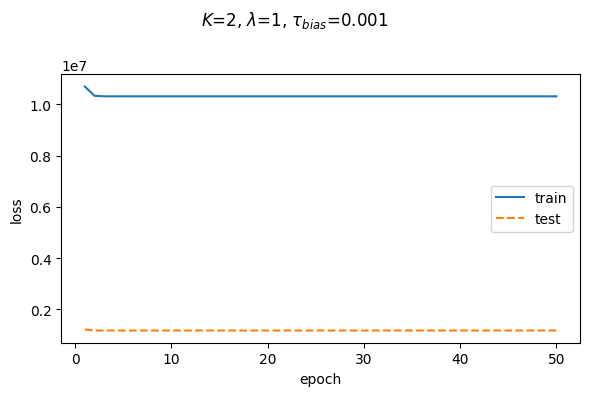

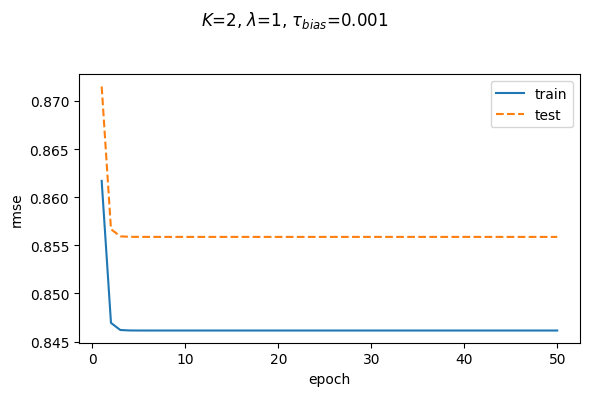

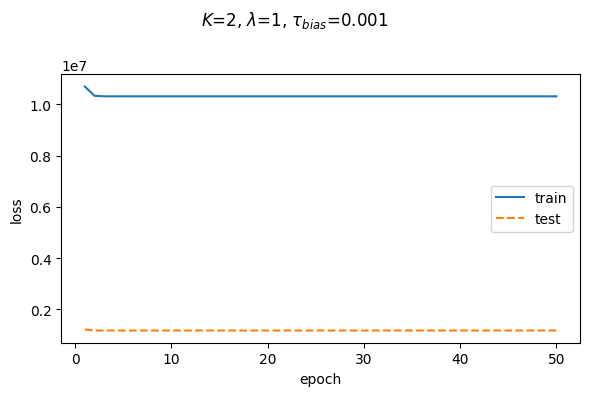

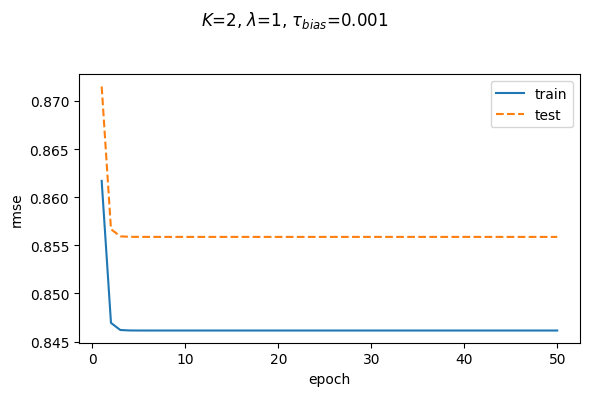

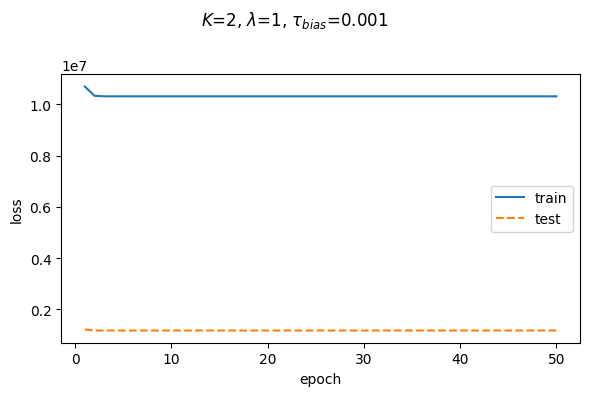

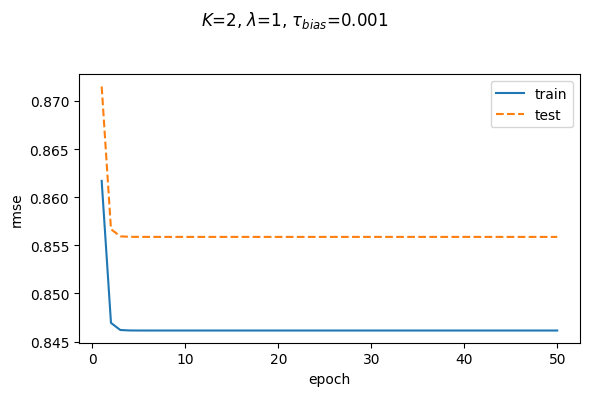

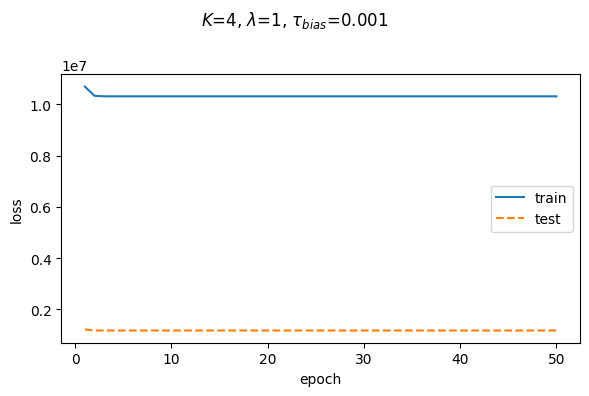

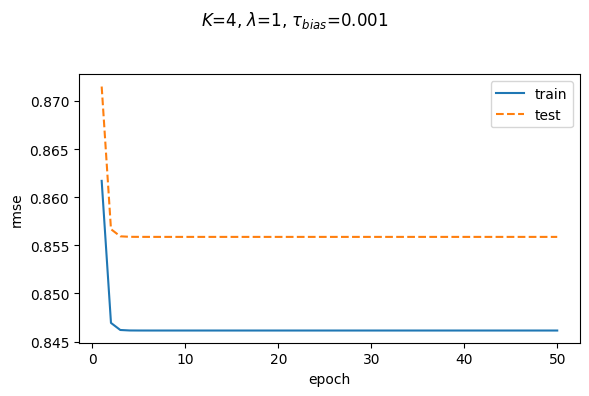

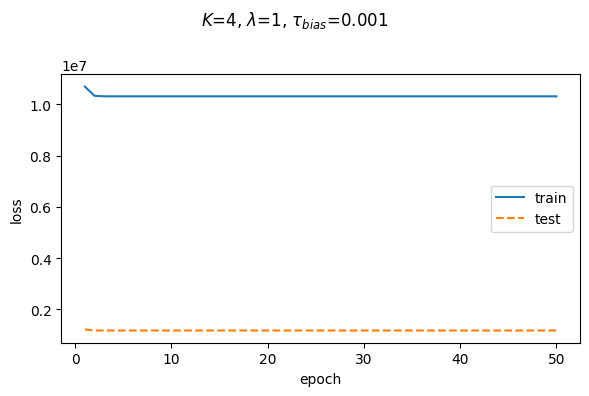

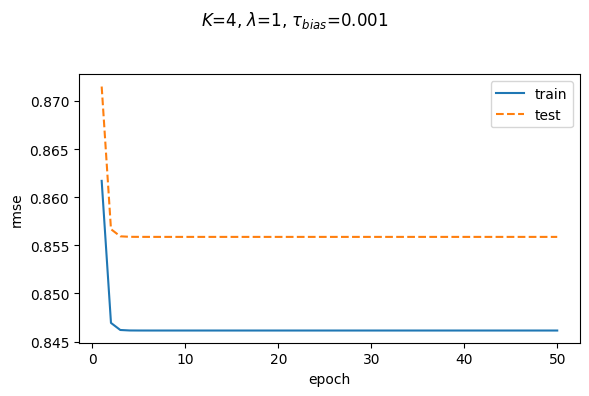

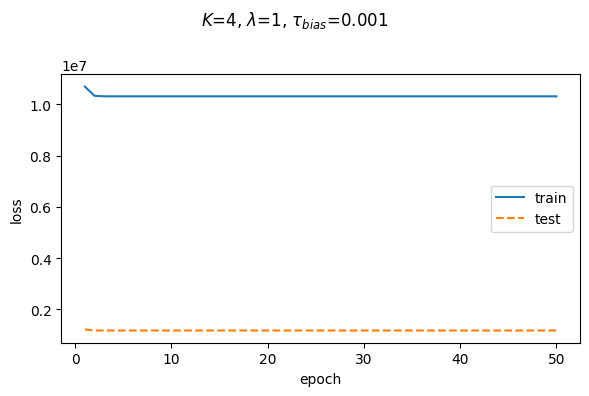

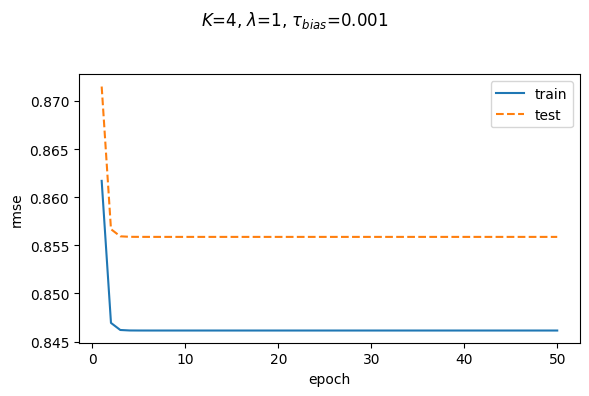

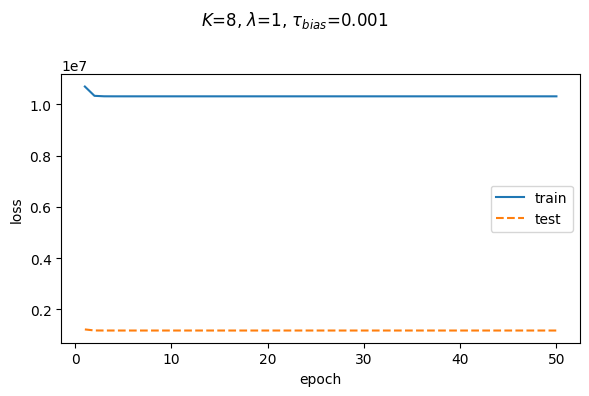

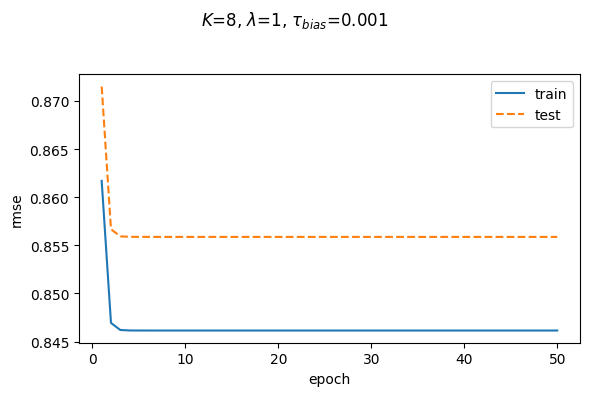

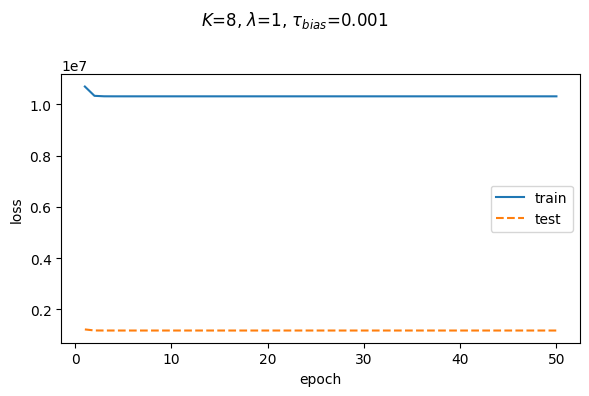

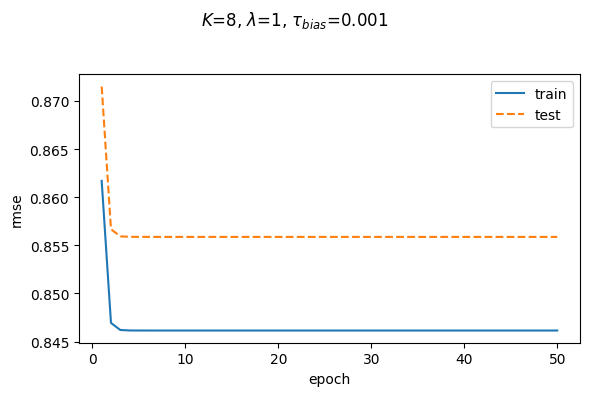

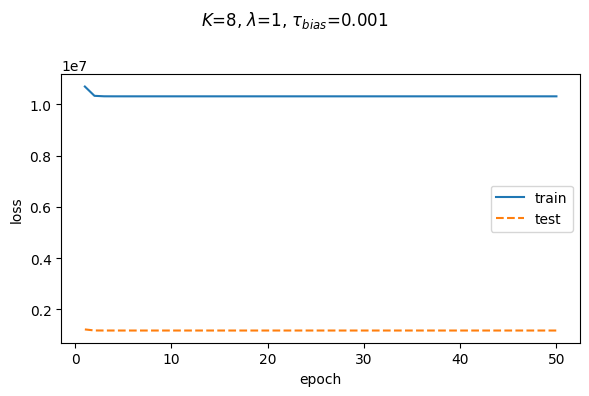

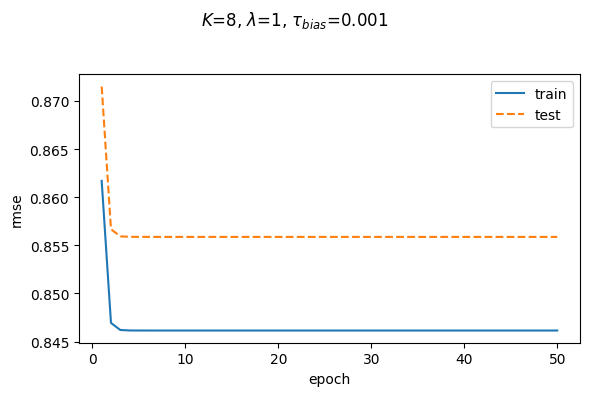

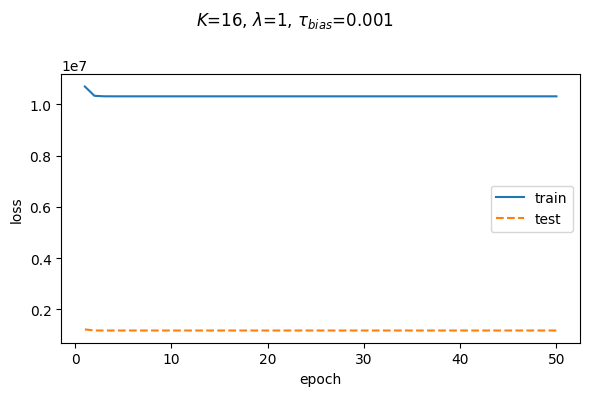

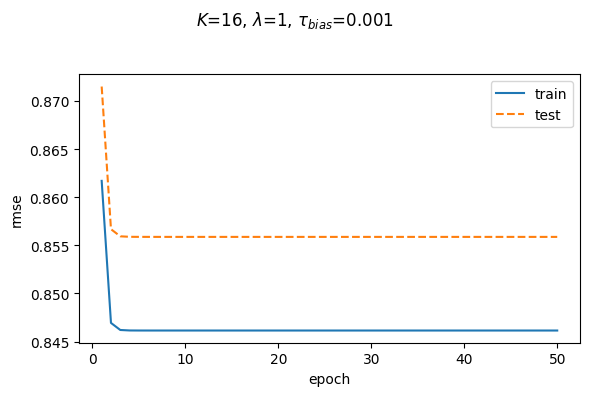

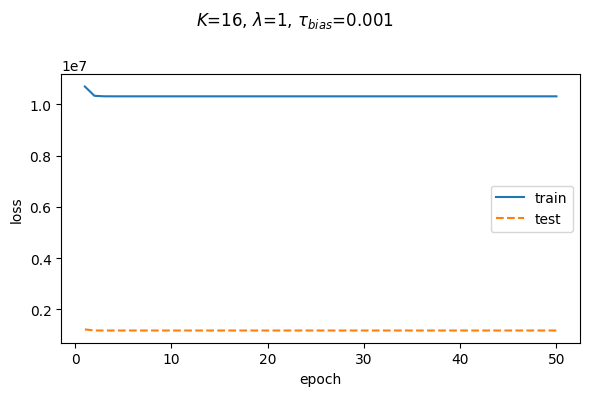

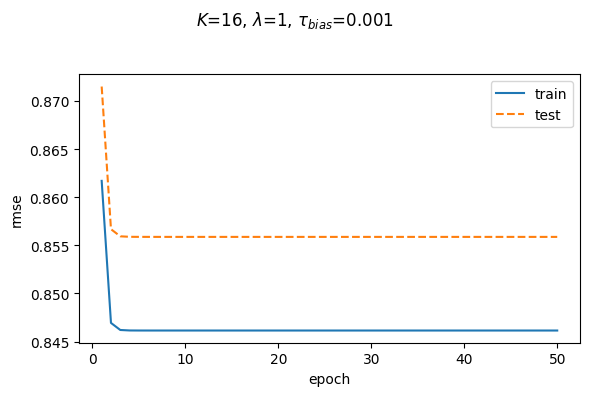

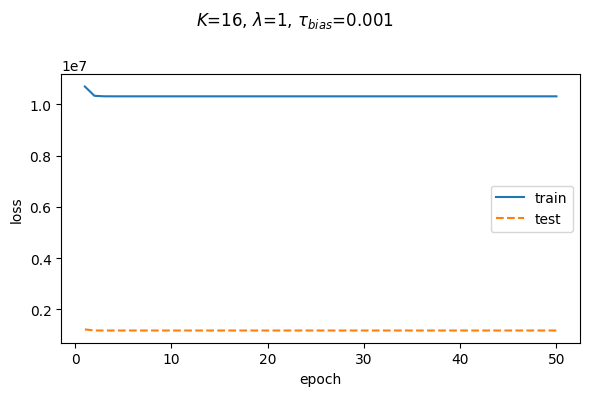

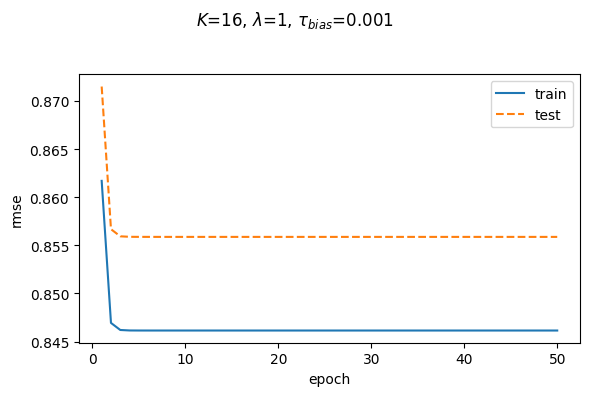

In [16]:
save = True
for path in loaded_model_paths:
    print(path)
    fitted_model = load_models(path)
    mode = fitted_model['mode']
    plot_folder = PLOT_FOLDER / "models" / mode

    toplot = "loss"
    save_model_metrics(fitted_model, toplot, plot_folder, save=save, overwrite=True)

    toplot = "rmse"
    save_model_metrics(fitted_model, toplot, plot_folder, save=save, overwrite=True)

# Model Trained with Embeddings

In [32]:
mode_dict = {
    0: "bias_only",
    1: "with_embeddings",
    2: "with_features"
}
mode = mode_dict[1]
models_folder_path = REMOTE_MODEL_FOLDER / mode

pattern = r"(=?best_nepochs).*latest.joblib$"
loaded_model_paths = get_models_path_filtered(models_folder_path, pattern=pattern)
print(f"Found {len(loaded_model_paths)} models in {models_folder_path} with pattern:{pattern}")
if len(loaded_model_paths) > 0:
    (
        train_last_loss_list,
        test_last_loss_list,
        train_last_rmse_list,
        test_last_rmse_list,
        precision_list,
        vector_penality_list,
        bias_penality_list,
        K_list,
        nepochs_list,
        mode_list
    ) = get_models_metrics(loaded_model_paths)

Found 15 models in /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m/models/with_embeddings with pattern:(=?best_nepochs).*latest.joblib$


## Best number epochs

In [33]:
records = []
result_save_path = Path(PROJECT_PATH) / 'model-selection'
datasplit_to = "test"
toplot = "rmse"
if datasplit_to == 'test':
    rmse_list = test_last_rmse_list
else:
    rmse_list = train_last_rmse_list
table_filepath = result_save_path / f"{datasplit_to}-best_epochs-{toplot}-{DATA_SIZE_STR}-{mode}.tex"



df = get_best_iteration_rmse_dataframe(
    nepochs_list,
    vector_penality_list,
    K_list,
    rmse_list,
    table_filepath,
    save=True,
)
display(df)


saved in /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/model-selection/test-best_epochs-nepochs-rmse-ml-32m-with_embeddings.tex


K,2,4,8,16,32
tau,,,,,
0.1,14 [0.8164],22 [0.7998],22 [0.7950],25 [0.8224],17 [0.9045]
1,23 [0.8144],23 [0.7975],22 [0.7855],19 [0.7900],12 [0.8305]
10,21 [0.8149],15 [0.7989],12 [0.7811],15 [0.7716],26 [0.7804]


RMSE Gap

In [34]:
records = []
result_save_path = Path(PROJECT_PATH) / 'model-selection'
toplot = "rmse_gap"

rmse_gap = np.array(train_last_rmse_list) - np.array(test_last_rmse_list)
table_filepath = result_save_path / f"nepochs-{toplot}-{DATA_SIZE_STR}-{mode}.tex"


df = get_best_iteration_rmse_dataframe(
    nepochs_list,
    vector_penality_list,
    K_list,
    rmse_gap,
    table_filepath,
    save=True,
)
display(df)

saved in /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/model-selection/nepochs-rmse_gap-ml-32m-with_embeddings.tex


K,2,4,8,16,32
tau,,,,,
0.1,14 [-0.0272],22 [-0.0439],22 [-0.0803],25 [-0.1612],17 [-0.3070]
1,23 [-0.0254],23 [-0.0395],22 [-0.0681],19 [-0.1240],12 [-0.2253]
10,21 [-0.0217],15 [-0.0326],12 [-0.0517],15 [-0.0875],26 [-0.1527]


## Grid Search on embeddings, vector penality

Plotting grids for mode:with_embeddings and data size:ml-32m (train)


Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/model-selection/train-rmse-grid-ml-32m-with_embeddings
Plotting grids for mode:with_embeddings and data size:ml-32m (test)
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/model-selection/test-rmse-grid-ml-32m-with_embeddings


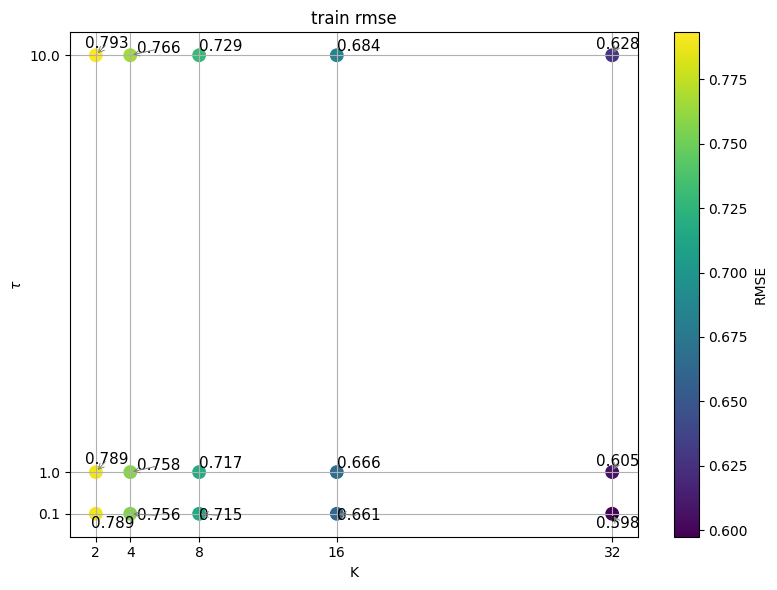

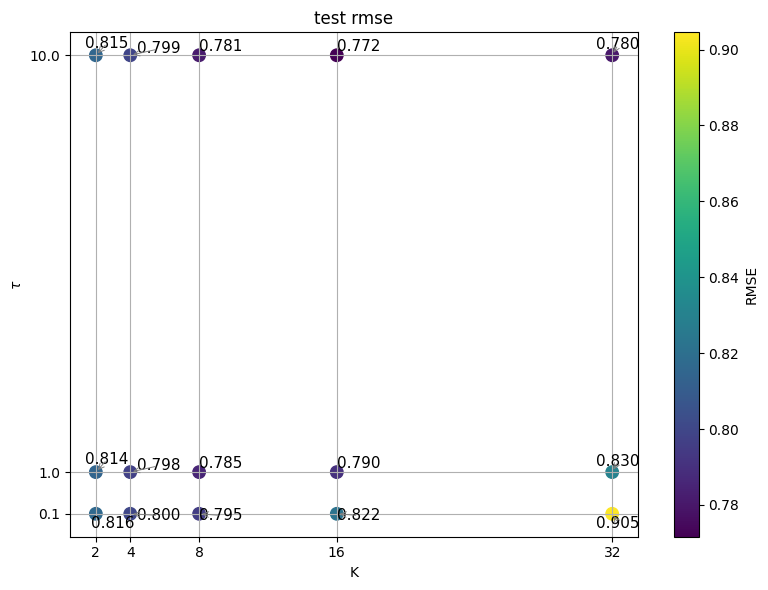

In [ ]:
if loaded_model_paths:
    plot_folder = PLOT_FOLDER / "model-selection"

    datasplit_to = "train"
    toplot = "rmse"
    plot_filepath = plot_folder / f"{datasplit_to}-{toplot}-grid-{DATA_SIZE_STR}-{mode}"
    title = f"{datasplit_to} {toplot}"
    print(f"Plotting grids for mode:{mode} and data size:{DATA_SIZE_STR} ({datasplit_to})")
    save_metrics_grid(
        K_list,
        vector_penality_list,
        train_last_rmse_list,
        plot_filepath,
        title=title,
        save=True,
        overwrite=True
    )
    datasplit_to = "test"
    toplot = "rmse"
    plot_filepath = plot_folder / f"{datasplit_to}-{toplot}-grid-{DATA_SIZE_STR}-{mode}"
    title = f"{datasplit_to} {toplot}"
    print(f"Plotting grids for mode:{mode} and data size:{DATA_SIZE_STR} ({datasplit_to})")
    save_metrics_grid(
        K_list,
        vector_penality_list,
        test_last_rmse_list,
        plot_filepath,
        title=title,
        save=True,
        overwrite=True
    )


## Save metrics plot

In [ ]:
mode_dict = {
    0: "bias_only",
    1: "with_embeddings",
    2: "with_features"
}
mode = mode_dict[1]
models_folder_path = MODEL_FOLDER /  mode

pattern = r"(=?best_nepochs).*latest.joblib$"
loaded_model_paths = get_models_path_filtered(models_folder_path, pattern=pattern)

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/models/with_embeddings/ml-32m-als-K32-best_nepochs17-maxiter50-lambda1-tau0.1-with_embeddings-latest.joblib
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_embeddings/loss-model-K32-best_nepochs17-maxiter50-lambda1-tau0.1-with_embeddings.pdf
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_embeddings/rmse-model-K32-best_nepochs17-maxiter50-lambda1-tau0.1-with_embeddings.pdf
/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/models/with_embeddings/ml-32m-als-K32-best_nepochs12-maxiter50-lambda1-tau1-with_embeddings-latest.joblib
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_embeddings/loss-model-K

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/recommender/models/model_io.py:294: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(1, figsize=(6, 4))


Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_embeddings/loss-model-K04-best_nepochs23-maxiter50-lambda1-tau1-with_embeddings.pdf
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_embeddings/rmse-model-K04-best_nepochs23-maxiter50-lambda1-tau1-with_embeddings.pdf
/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/models/with_embeddings/ml-32m-als-K04-best_nepochs15-maxiter50-lambda1-tau10-with_embeddings-latest.joblib
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_embeddings/loss-model-K04-best_nepochs15-maxiter50-lambda1-tau10-with_embeddings.pdf
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_embeddings/rmse-m

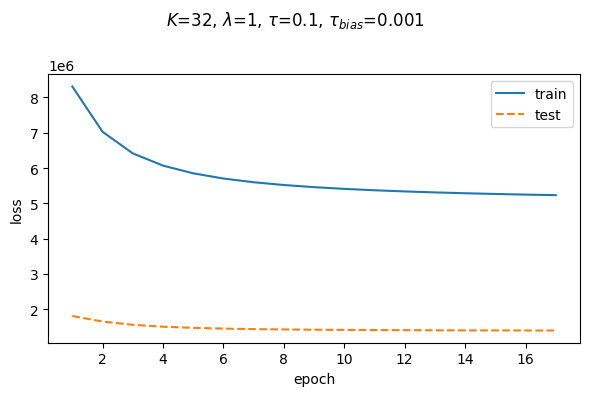

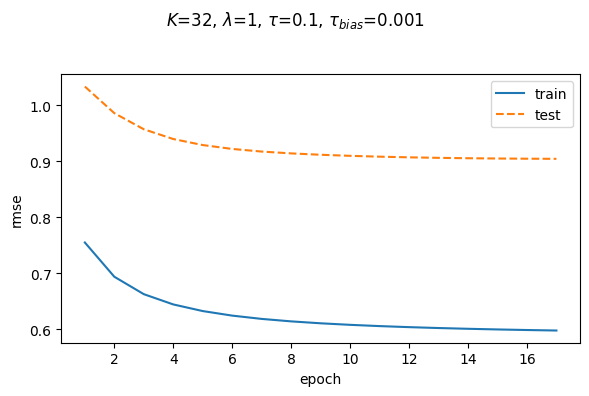

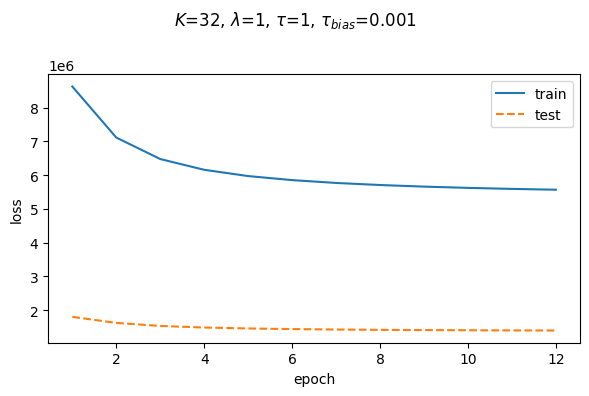

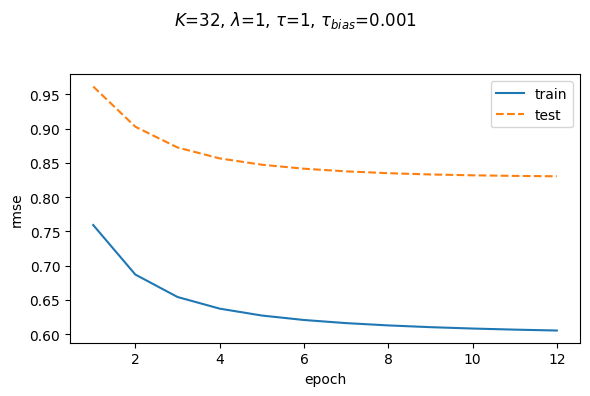

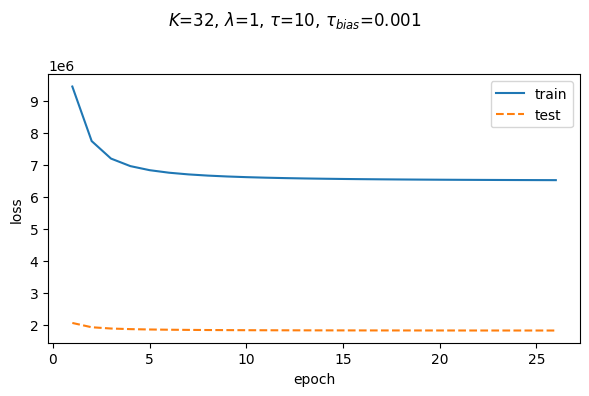

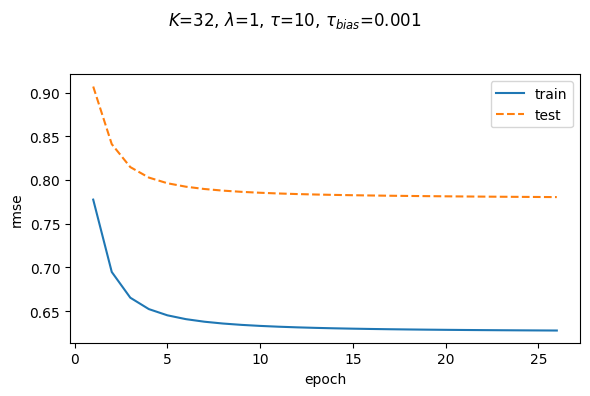

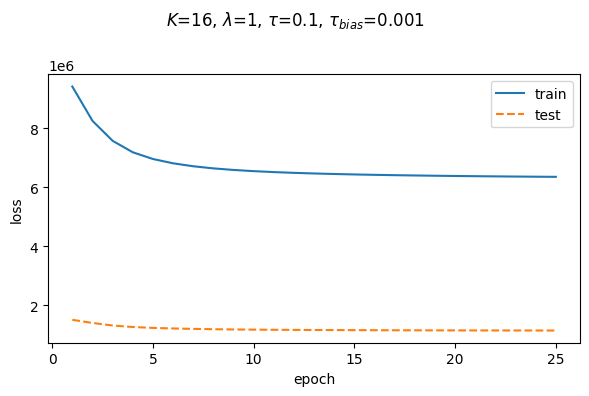

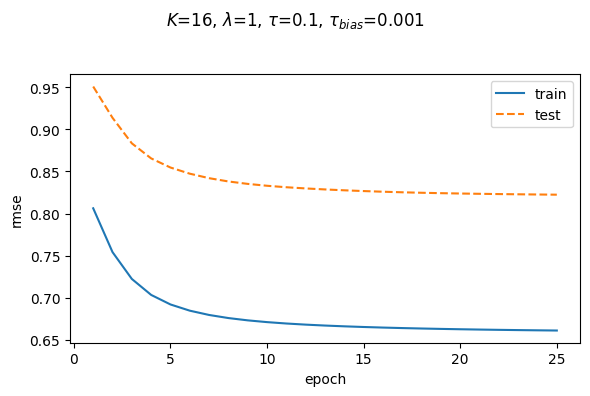

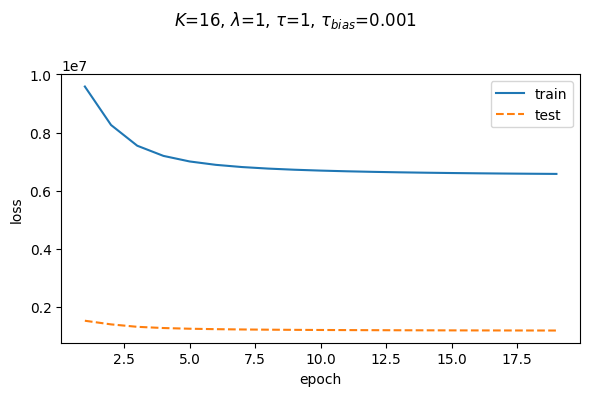

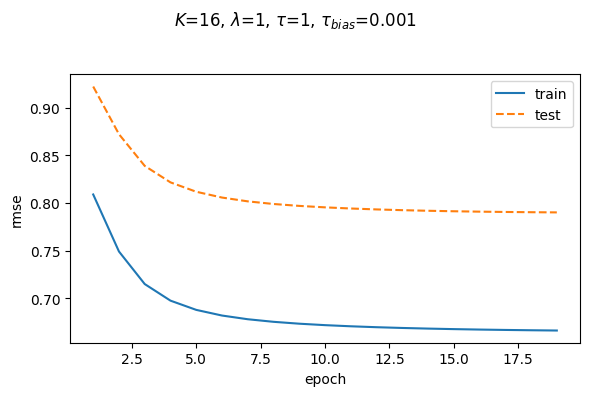

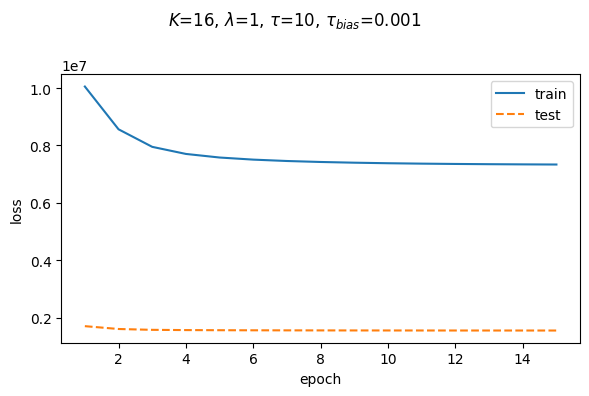

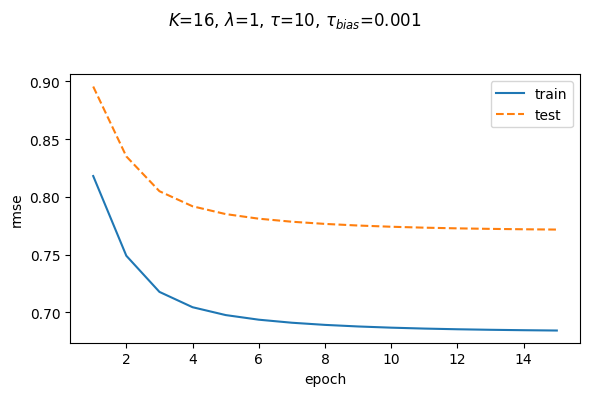

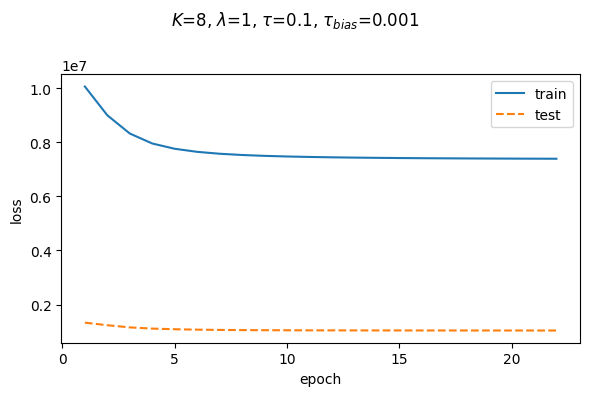

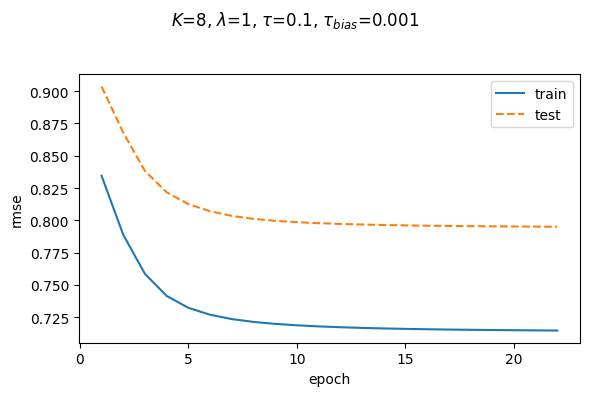

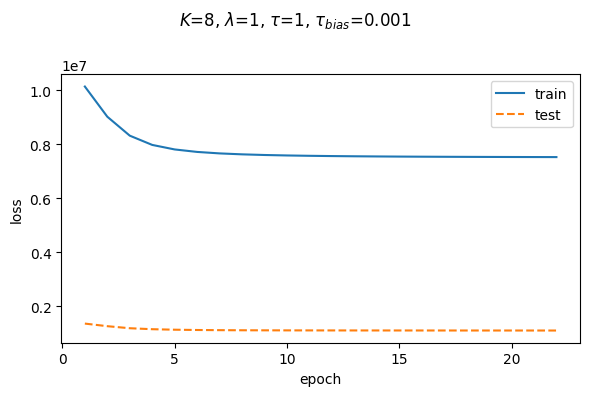

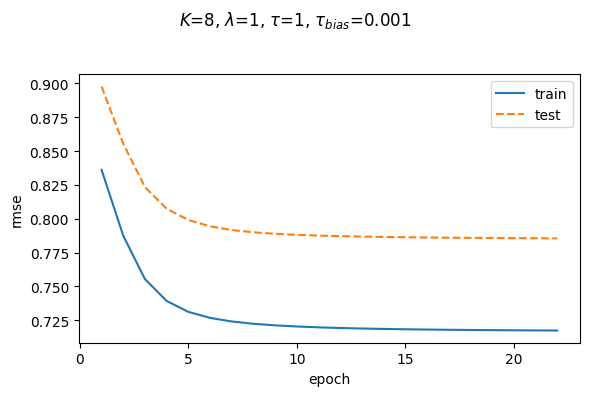

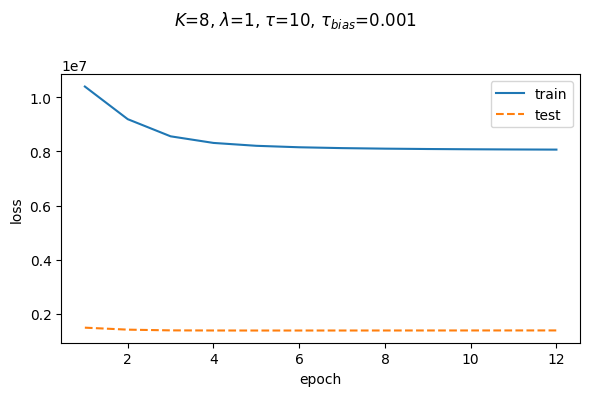

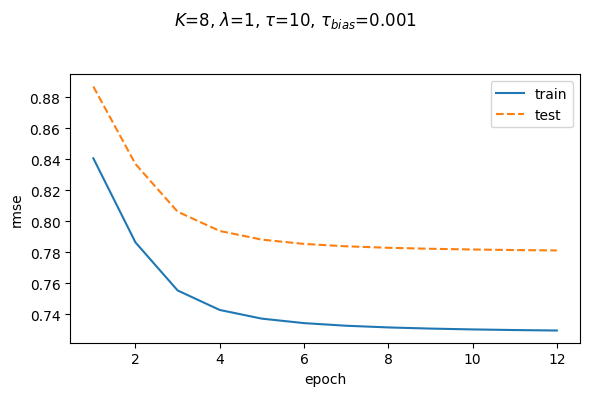

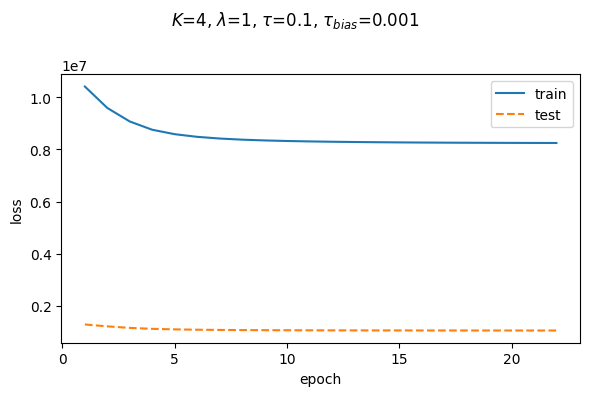

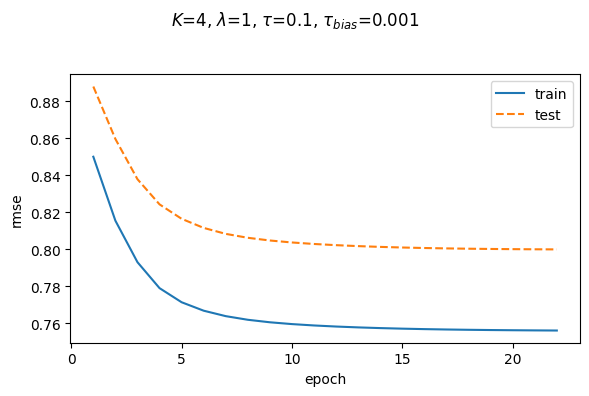

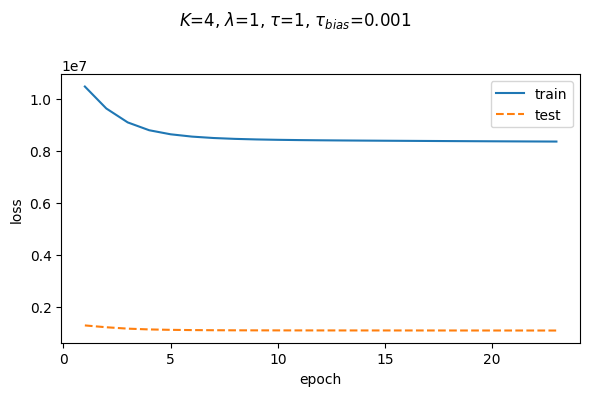

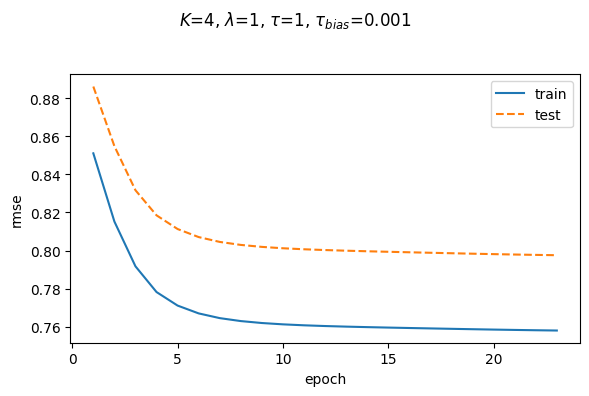

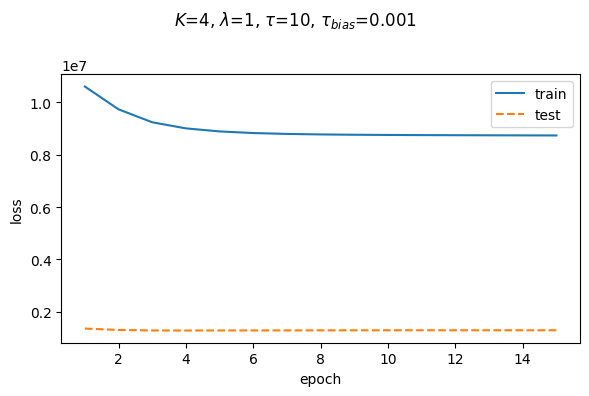

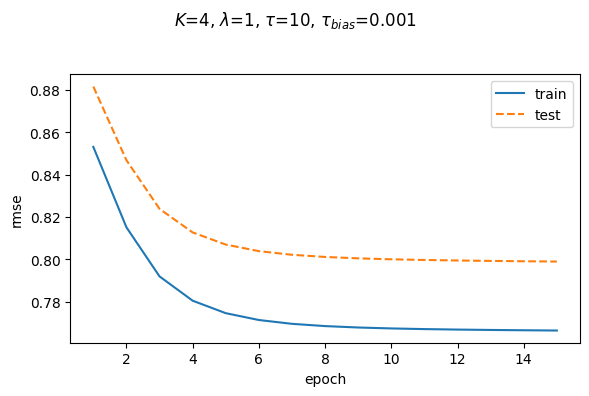

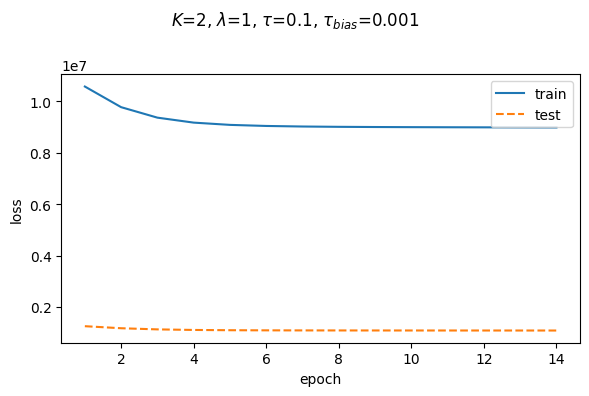

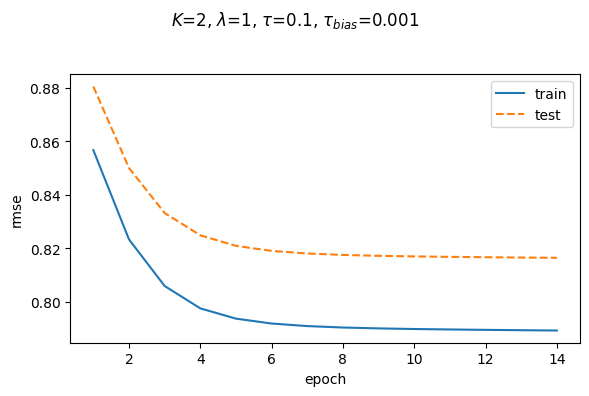

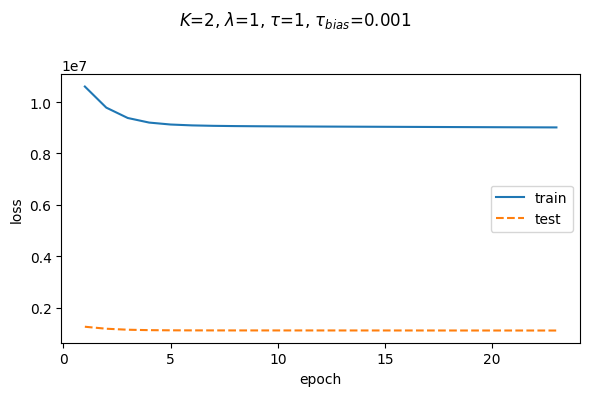

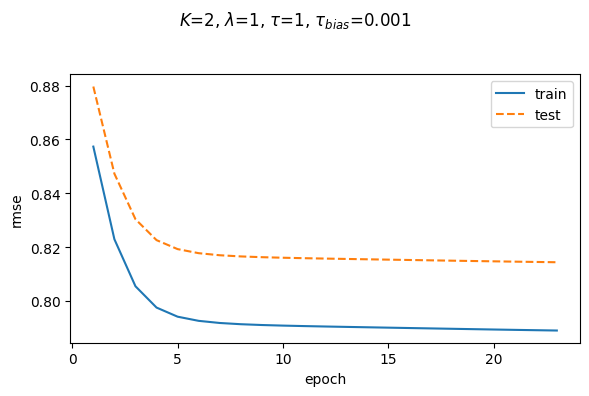

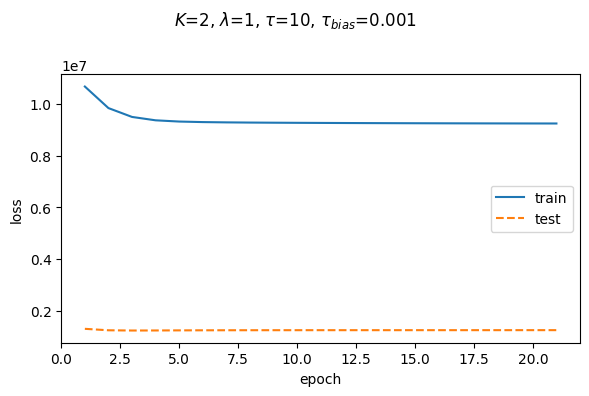

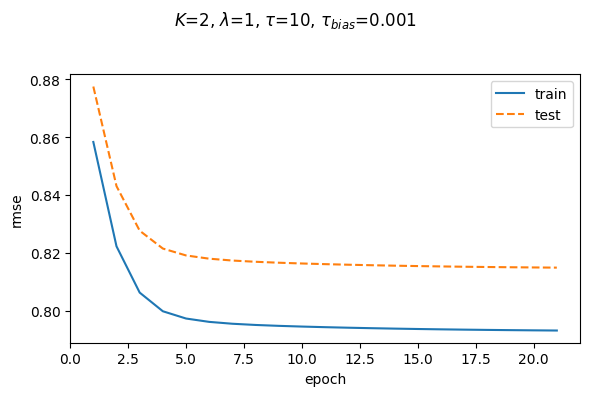

In [ ]:
save = True
for path in loaded_model_paths:
    print(path)
    fitted_model = load_models(path)
    mode = fitted_model['mode']
    plot_folder = PLOT_FOLDER / "models" / mode

    toplot = "loss"
    save_model_metrics(fitted_model, toplot, plot_folder, save=save, overwrite=True)

    toplot = "rmse"
    save_model_metrics(fitted_model, toplot, plot_folder, save=save, overwrite=True)

# Model Trained with Feature

In [29]:
mode_dict = {
    0: "bias_only",
    1: "with_embeddings",
    2: "with_features"
}
mode = mode_dict[2]
models_folder_path = MODEL_FOLDER / mode

pattern = r"(=?best_nepochs).*latest.joblib$"
loaded_model_paths = get_models_path_filtered(models_folder_path, pattern=pattern)
print(f"Found {len(loaded_model_paths)} models in {models_folder_path} with pattern:{pattern}")
if len(loaded_model_paths) > 0:
    (
        train_last_loss_list,
        test_last_loss_list,
        train_last_rmse_list,
        test_last_rmse_list,
        precision_list,
        vector_penality_list,
        bias_penality_list,
        K_list,
        iteration_list,
        mode_list
    ) = get_models_metrics(loaded_model_paths)

Found 15 models in /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/models/with_features with pattern:(=?best_nepochs).*latest.joblib$


## Best number epochs

In [30]:
records = []
result_save_path = Path(PROJECT_PATH) / 'model-selection'
datasplit_to = "test"
toplot = "rmse"
if datasplit_to == 'test':
    rmse_list = test_last_rmse_list
else:
    rmse_list = train_last_rmse_list
table_filepath = result_save_path / f"{datasplit_to}-best_epochs-{toplot}-{DATA_SIZE_STR}-{mode}.tex"



df = get_best_iteration_rmse_dataframe(
    nepochs_list,
    vector_penality_list,
    K_list,
    rmse_list,
    table_filepath,
    save=True,
)
display(df)


saved in /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/model-selection/test-best_epochs-rmse-ml-32m-with_features.tex


K,2,4,8,16,32
tau,,,,,
0.1,21 [0.8194],17 [0.8075],22 [0.7946],15 [0.8193],26 [0.9003]
1,23 [0.8185],12 [0.8048],23 [0.7863],22 [0.7899],25 [0.8290]
10,14 [0.8172],12 [0.8042],15 [0.7806],22 [0.7716],19 [0.7815]


RMSE Gap

In [31]:
records = []
result_save_path = Path(PROJECT_PATH) / 'model-selection'
toplot = "rmse_gap"

rmse_gap = np.array(train_last_rmse_list) - np.array(test_last_rmse_list)
table_filepath = result_save_path / f"nepochs-{toplot}-{DATA_SIZE_STR}-{mode}.tex"


df = get_best_iteration_rmse_dataframe(
    nepochs_list,
    vector_penality_list,
    K_list,
    rmse_gap,
    table_filepath,
    save=True,
)
display(df)

saved in /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/model-selection/nepochs-rmse_gap-ml-32m-with_features.tex


K,2,4,8,16,32
tau,,,,,
0.1,21 [-0.0267],17 [-0.0371],22 [-0.0731],15 [-0.1549],26 [-0.2996]
1,23 [-0.0242],12 [-0.0334],23 [-0.0632],22 [-0.1193],25 [-0.2219]
10,14 [-0.0211],12 [-0.0278],15 [-0.0526],22 [-0.0861],19 [-0.1526]


## Grid Search on embeddings, vector penality

Plotting grids for mode:with_features and data size:ml-32m (train)
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/model-selection/train-rmse-grid-ml-32m-with_features
Plotting grids for mode:with_features and data size:ml-32m (test)
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/model-selection/test-rmse-grid-ml-32m-with_features


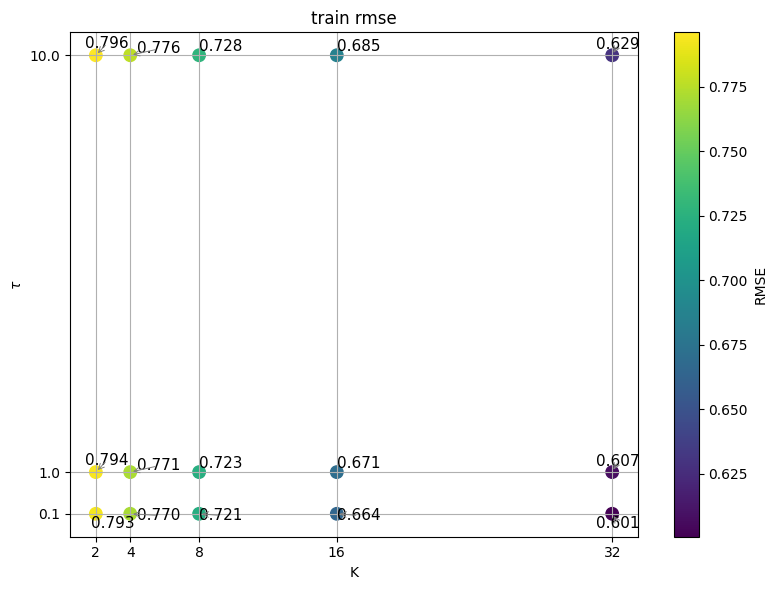

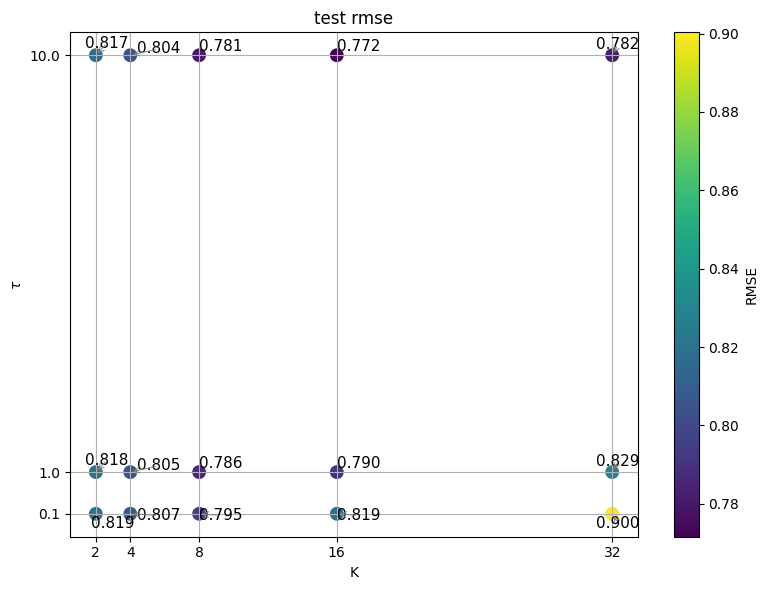

In [ ]:
if loaded_model_paths:
    plot_folder = PLOT_FOLDER / "model-selection"

    datasplit_to = "train"
    toplot = "rmse"
    plot_filepath = plot_folder / f"{datasplit_to}-{toplot}-grid-{DATA_SIZE_STR}-{mode}"
    title = f"{datasplit_to} {toplot}"
    print(f"Plotting grids for mode:{mode} and data size:{DATA_SIZE_STR} ({datasplit_to})")
    save_metrics_grid(
        K_list,
        vector_penality_list,
        train_last_rmse_list,
        plot_filepath,
        title=title,
        save=True,
        overwrite=True
    )
    datasplit_to = "test"
    toplot = "rmse"
    plot_filepath = plot_folder / f"{datasplit_to}-{toplot}-grid-{DATA_SIZE_STR}-{mode}"
    title = f"{datasplit_to} {toplot}"
    print(f"Plotting grids for mode:{mode} and data size:{DATA_SIZE_STR} ({datasplit_to})")
    save_metrics_grid(
        K_list,
        vector_penality_list,
        test_last_rmse_list,
        plot_filepath,
        title=title,
        save=True,
        overwrite=True
    )


## SAVE METRICS

In [ ]:
mode_dict = {
    0: "bias_only",
    1: "with_embeddings",
    2: "with_features"
}
mode = mode_dict[2]
models_folder_path = MODEL_FOLDER /  mode

pattern = r"(=?best_nepochs).*latest.joblib$"
loaded_model_paths = get_models_path_filtered(models_folder_path, pattern=pattern)

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/models/with_features/ml-32m-als-K32-best_nepochs14-maxiter50-lambda1-tau0.1-with_features-latest.joblib
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_features/loss-model-K32-best_nepochs14-maxiter50-lambda1-tau0.1-with_features.pdf
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_features/rmse-model-K32-best_nepochs14-maxiter50-lambda1-tau0.1-with_features.pdf
/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/models/with_features/ml-32m-als-K32-best_nepochs11-maxiter50-lambda1-tau1-with_features-latest.joblib
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_features/loss-model-K32-best_nepochs11-

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/recommender/models/model_io.py:294: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(1, figsize=(6, 4))


Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_features/loss-model-K04-best_nepochs8-maxiter50-lambda1-tau1-with_features.pdf
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_features/rmse-model-K04-best_nepochs8-maxiter50-lambda1-tau1-with_features.pdf
/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/models/with_features/ml-32m-als-K04-best_nepochs10-maxiter50-lambda1-tau10-with_features-latest.joblib
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_features/loss-model-K04-best_nepochs10-maxiter50-lambda1-tau10-with_features.pdf
Plot saved to /content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/models/with_features/rmse-model-K04-best_nepoch

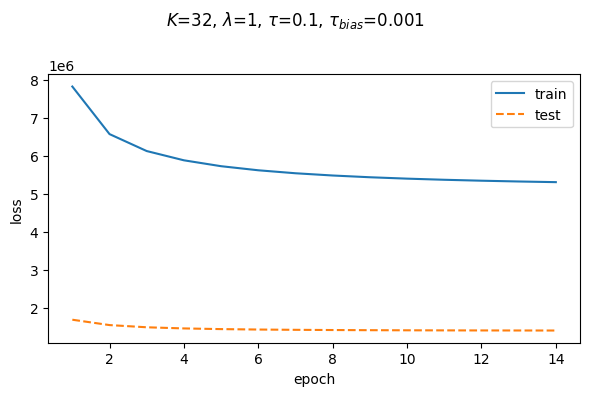

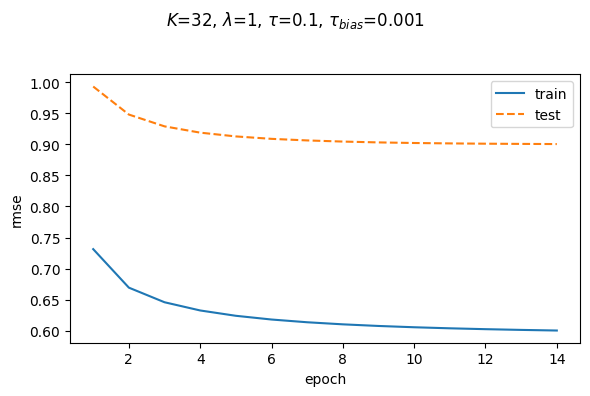

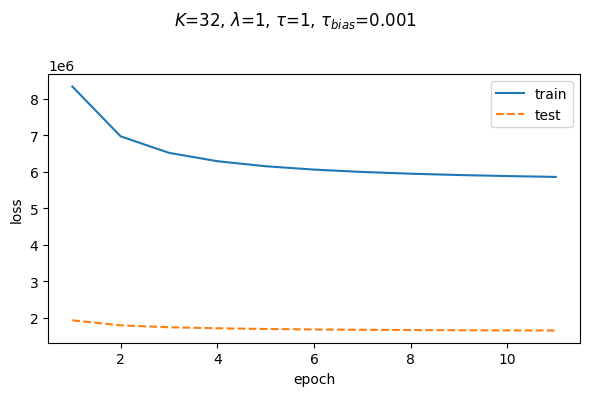

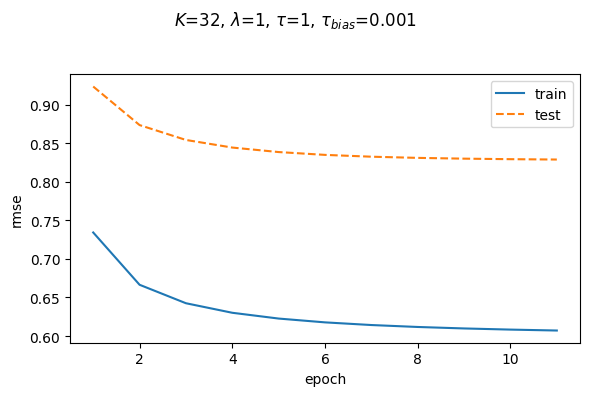

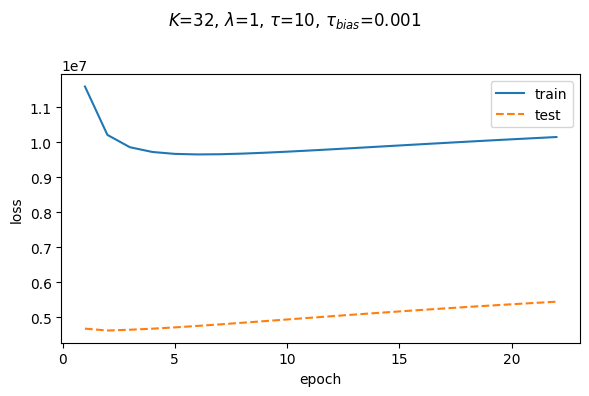

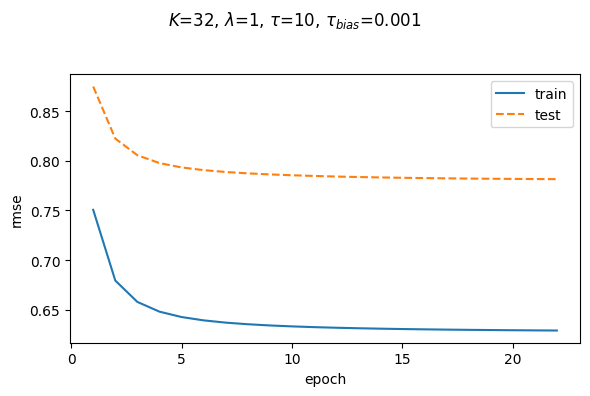

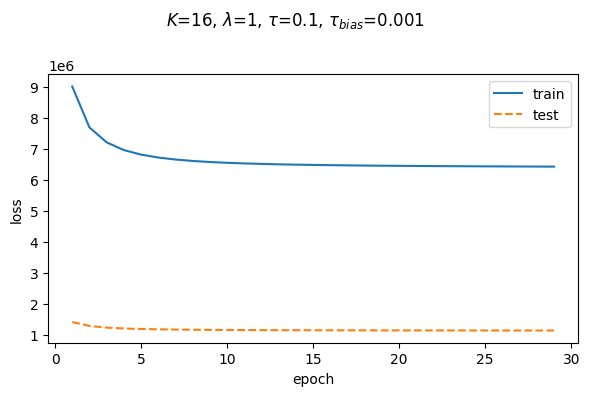

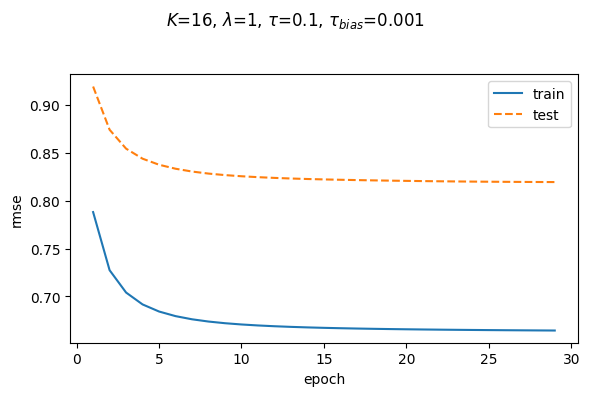

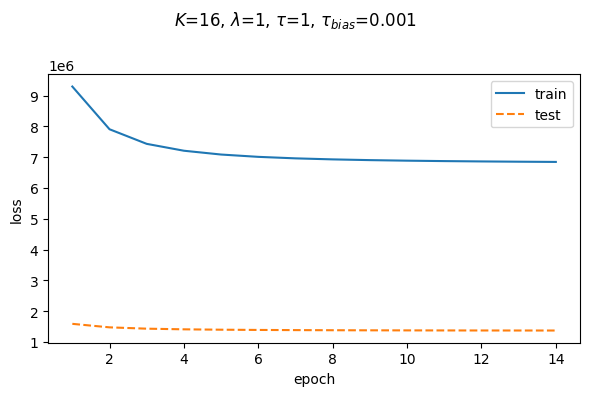

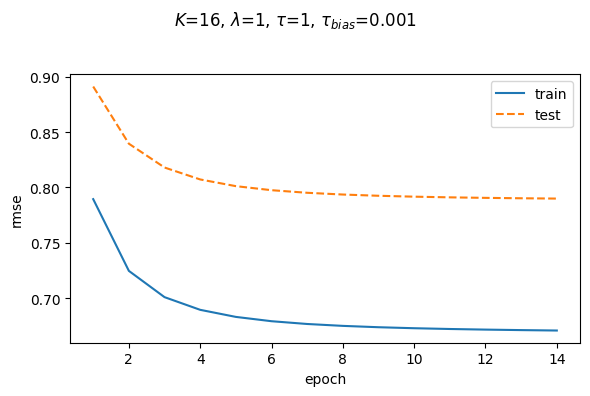

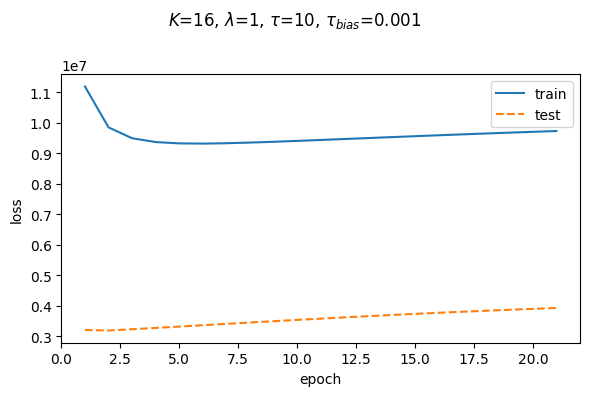

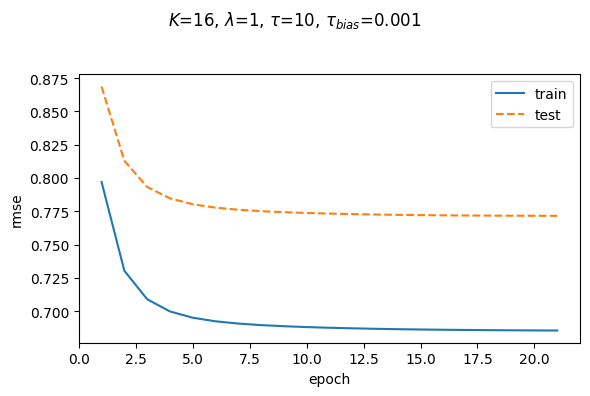

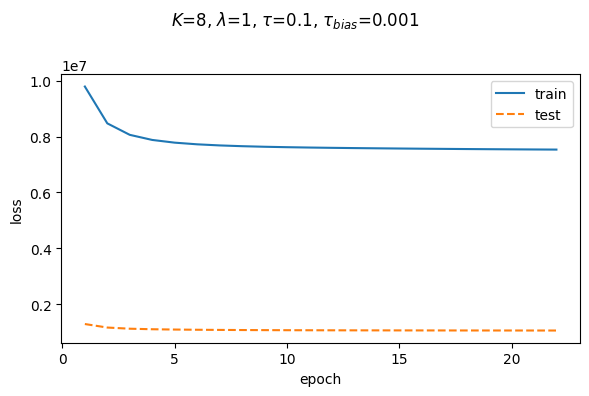

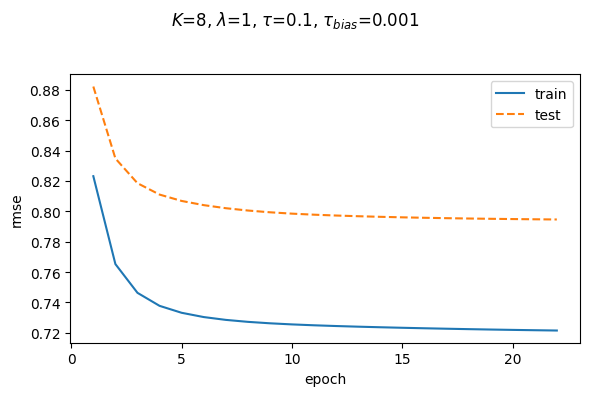

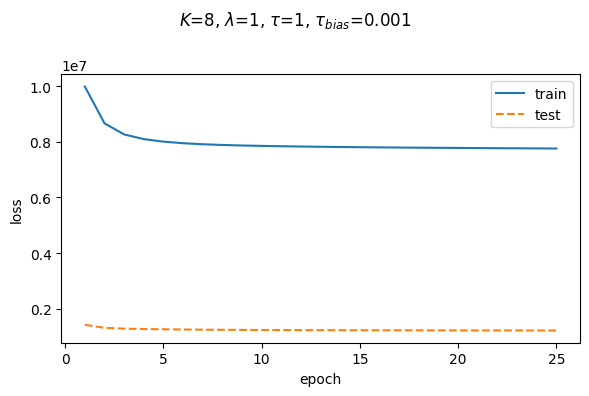

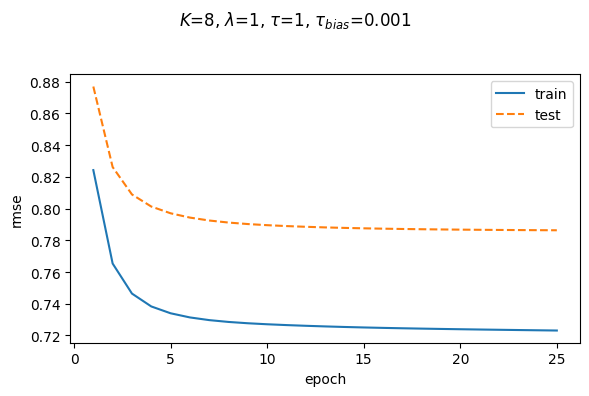

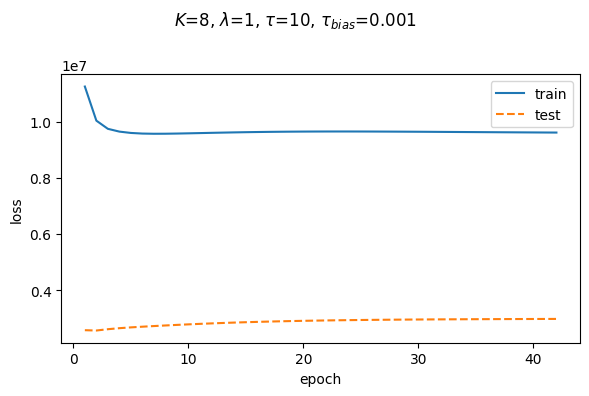

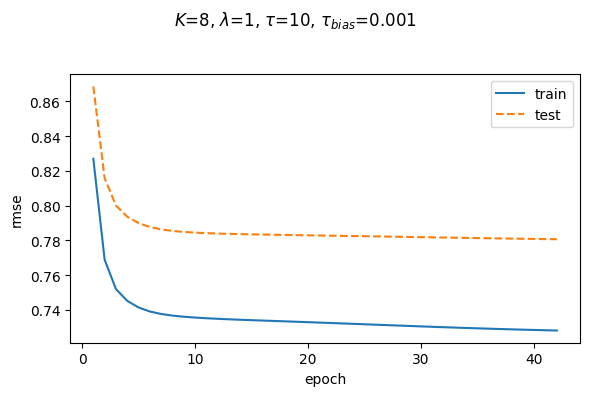

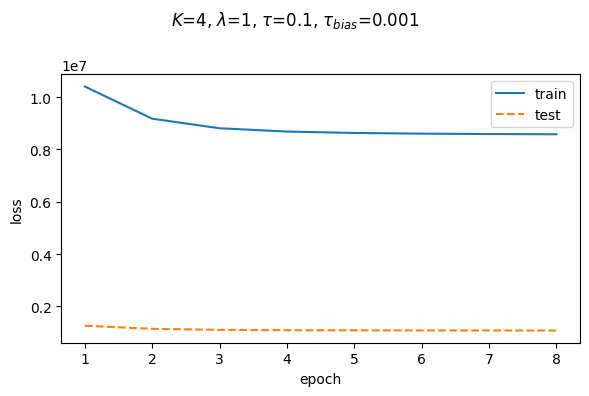

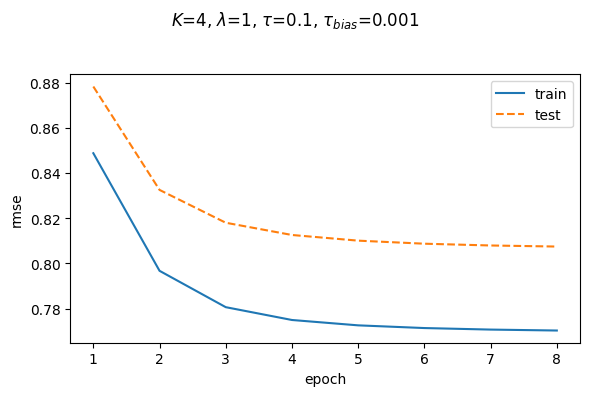

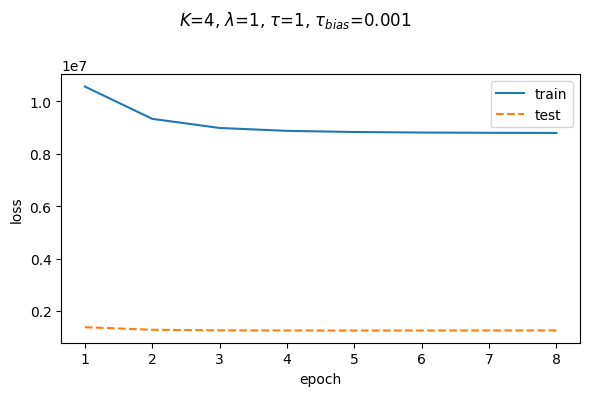

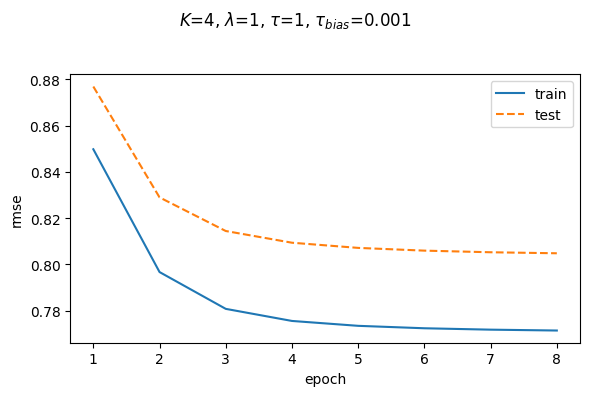

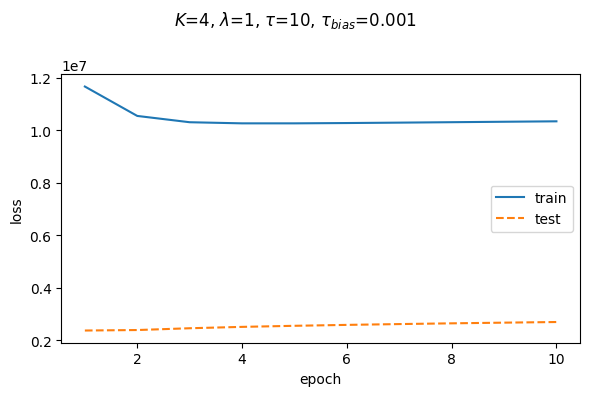

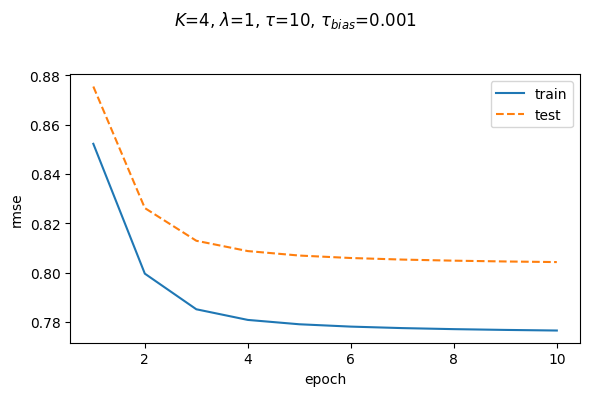

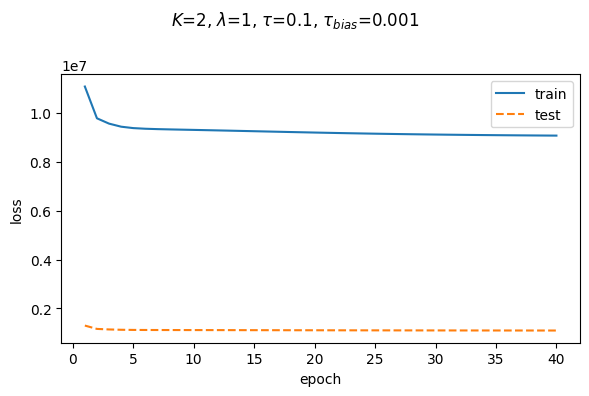

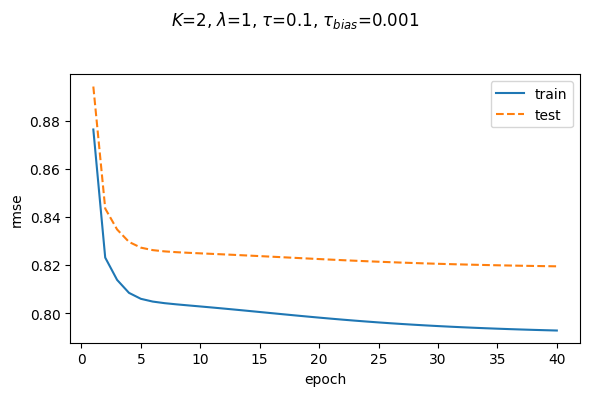

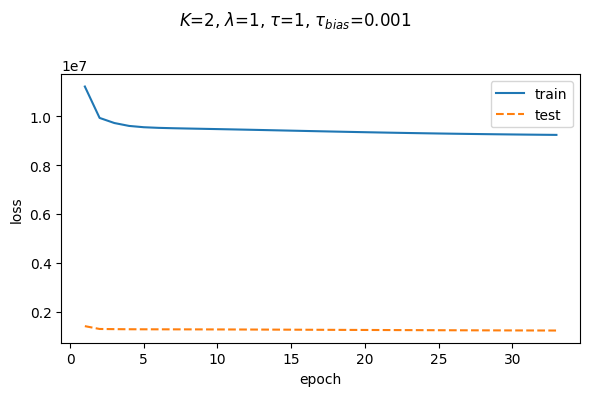

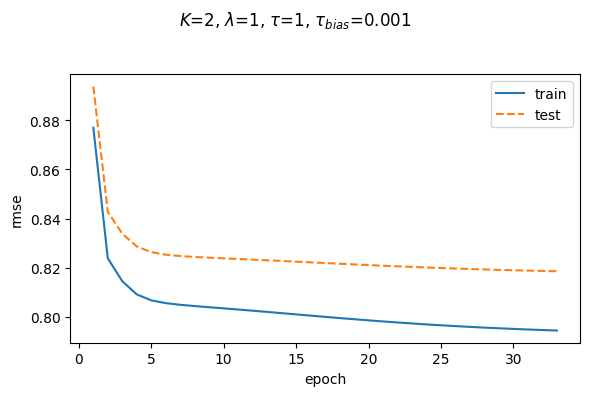

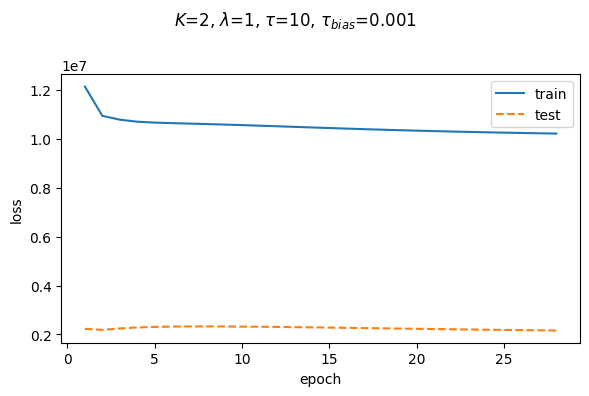

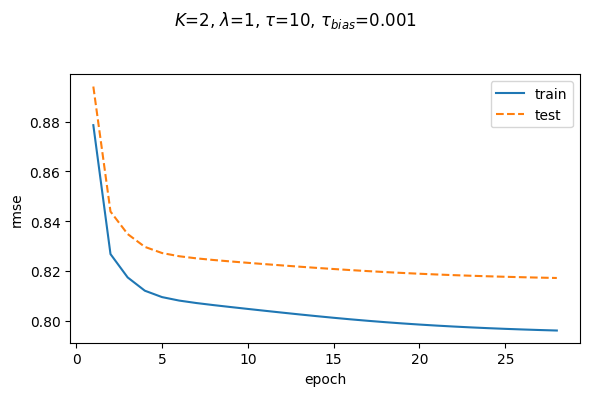

In [ ]:
save = True
for path in loaded_model_paths:
    print(path)
    fitted_model = load_models(path)
    mode = fitted_model['mode']
    plot_folder = PLOT_FOLDER / "models" / mode

    toplot = "loss"
    save_model_metrics(fitted_model, toplot, plot_folder, save=save, overwrite=True)

    toplot = "rmse"
    save_model_metrics(fitted_model, toplot, plot_folder, save=save, overwrite=True)